# **TP1 - Variable Types & Descriptive Statistics**

<b>Exploratory Data Analysis & Unsuperivsed Learning </b><br>
**Course: Dr. HAS Sothea**

-------

**Objective**: This initial practical session is designed to enhance your understanding of various data variable types and the corresponding statistical and graphical tools suitable for each type.

---------

> **The `Jupyter Notebook` for this TP can be downloaded here: [TP1-Gapminder](https://hassothea.github.io/M1_DAS_EDA_ITC/TPs/TP1_Variable_Types_Descriptive_Statistics.ipynb)**.

-------

# 1. `Gapminder` dataset

[`Gapminder`](https://pypi.org/project/gapminder/) is an excerpt of data available at [https://gapminder.org](https://www.gapminder.org/). For each of $142$ countries (`country`), the package provides values for life expectancy (`lifeExp`), GDP per capita (`gdpPercap`), and population (`pop`), every five years, from $1952$ to $2007$ (`year`). It is initially used in [Jennifer Bryan's excellent `gapminder` teaching package for R](https://github.com/jennybc/gapminder/) ([`ggplot`](https://ggplot2.tidyverse.org/), [`tidyverse`](https://www.tidyverse.org/), and more). For more information about `gapminder`: 
- Documentation: [https://www.gapminder.org/data/documentation/](https://www.gapminder.org/data/documentation/)
- A short demonstration video is available here: [Hans Rosling's 200 Countries, 200 Years, 4 Minutes - The Joy of Stats - BBC Four](https://youtu.be/jbkSRLYSojo?si=qipg08VIi999hEgo).

In [1]:
# useful packages
import numpy as np # import numpy then call it 'np' for short
import pandas as pd # import pandas from then call it 'pd' for short

# %pip install gapminder  (for installing gapminder if you haven't had one)
from gapminder import gapminder
gapminder.sample(3)

c:\Users\MSI\itc_intro_to_data_science\.venv\Lib\site-packages\gapminder\data.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


,country,continent,year,lifeExp,pop,gdpPercap
1416,Spain,Europe,1952,64.940,28549870,3834.034742
84,Bahrain,Asia,1952,50.939,120447,9867.084765
1304,Sao Tome and Principe,Africa,1992,62.742,125911,1428.777814


In [3]:
from gapminder import gapminder
data = gapminder 
data.head(10)

,country,continent,year,lifeExp,pop,gdpPercap
0,Afghanistan,Asia,1952,28.801,8425333,779.445314
1,Afghanistan,Asia,1957,30.332,9240934,820.853030
2,Afghanistan,Asia,1962,31.997,10267083,853.100710
3,Afghanistan,Asia,1967,34.020,11537966,836.197138
4,Afghanistan,Asia,1972,36.088,13079460,739.981106
5,Afghanistan,Asia,1977,38.438,14880372,786.113360
6,Afghanistan,Asia,1982,39.854,12881816,978.011439
7,Afghanistan,Asia,1987,40.822,13867957,852.395945
8,Afghanistan,Asia,1992,41.674,16317921,649.341395
9,Afghanistan,Asia,1997,41.763,22227415,635.341351


----------

# 2. Variable types

`EDA` involves summarizing and visualizing data to uncover patterns, detect anomalies, and understand relationships between variables. Statistical summaries, such as mean, median, and standard deviation, are essential tools in this process.

- Which variables are considered quantitative and which are qualitative? 

> Hint: You can check the default column types by using `gapminder.dtypes`. But this may not be accurate because some categorical data may be encoded using numerical values.

In [4]:
# To do
data.dtypes

country          str
continent        str
year           int64
lifeExp      float64
pop            int64
gdpPercap    float64
dtype: object

> **Your response**: 

## 2.1 Quantitative variables

1. In year 2002, 
- Compute suitable statistics for each quantitative variable (excluding `year`) to obtain an overall summary.
- Recall the definitions of **skewness** and **kurtosis** introduced in the course. 
- Compute these metrics for each quantitative variable and explain the distribution of each variable based on these values.

In [6]:
# filter rows at year 2002
# method 1 
data[data['year'] == 2002] # use logical index in the data set to filter rows

# method 2: use 'query': select rows that satisfy that statisfy the given condition.
data2002 = data.query('year == 2002')

# *Answer:*
Statistical summary

In [11]:
data2002[['lifeExp', 'pop', 'gdpPercap']].describe() # describe the three variables in data2002

,lifeExp,pop,gdpPercap
count,142.000000,1.420000e+02,142.000000
mean,65.694923,4.145759e+07,9917.848365
std,12.279823,1.408483e+08,11154.114865
min,39.193000,1.703720e+05,241.165876
25%,55.522250,4.173506e+06,1409.567264
50%,70.825500,1.037292e+07,5319.804524
75%,75.459250,2.654556e+07,13359.512258
max,82.000000,1.280400e+09,44683.975250


**Interpretation:**
- For 'lifeExp', the population of healthiest country in 2002 are expected to live upto 82 years old while the unhealthiest country has life expectancy around 39 years old. As the median is around 71 years old which is higher than midpoint (82+39)/2 = 60.5 years old, indicating that most country were on the healthy side. Finally, the unhealthiest country with 39 years old life expectancy seems to be an outliers as the average(65) is lower than the median.

- 'Skewness (symmetry) and Kurtosis (Tail of distribution)'

- if a data is well symetric, then 'Skewness' $/aprox 0$

In [ ]:
# compute skewness 
from scipy.stats import skew

2. Graphically represent the distribution of each variable for the year $2002$. After plotting the distributions, provide a brief explanation for each variable.

<Axes: xlabel='lifeExp', ylabel='Count'>

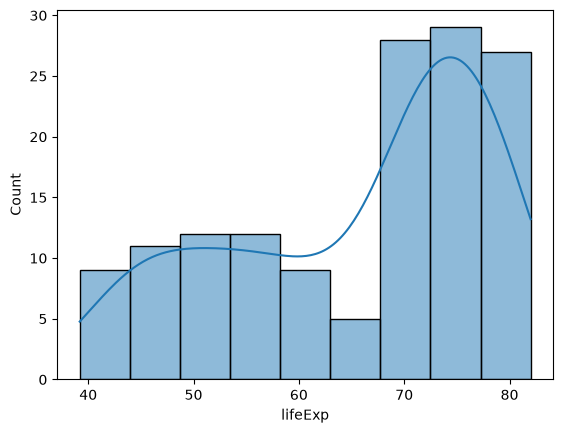

In [19]:
import seaborn as sns
# LifeExp 

sns.histplot( # choose graph
    data=data2002, # give data
    x='lifeExp', # choose column
    kde=True
)

3. According to the data, in 2002:
- Which country is the richest? 
- Which country is the poorest?
- Which country is the healthiest?
- Which country is the unhealthiest?

In [23]:
# Method 1
## data2002[data2002['gdpPercap']==data2002['gdpPercap'].max()] # find the row with the maximum gdpPercap

# Method 2
data2002.query('lifeExp == lifeExp.max()') # find the row with the maximum life expectancy

,country,continent,year,lifeExp,pop,gdpPercap
802,Japan,Asia,2002,82.0,127065841,28604.5919


In [24]:
# Find the Cambodia lifeExp in 2002
data2002.query('country == "Cambodia"') # find the row with the country

,country,continent,year,lifeExp,pop,gdpPercap
226,Cambodia,Asia,2002,56.752,12926707,896.226015


4. Repeat the previous question for the year 1977. Before computing, can you guess which country had the lowest life expectancy around that year?

In [ ]:
# Find the lowest lifeExp in 1977 
data.query('year == 1977').query('lifeExp == lifeExp.min()') # find the row with the minimum life expectancy

,country,continent,year,lifeExp,pop,gdpPercap
221,Cambodia,Asia,1977,31.22,6978607,524.972183


## 2.2. Qualitative variables

Qualitative variables are simpler than the quantitative ones, as we primarily focus on the proportion or frequency of each category. In our dataset, the existing qualitative variables are not suitable for analysis because they are repeated each year. Therefore, we will create three new qualitative variables associated with the three quantitative columns by copping them into three categories each.

In year 2002,

1. Add the following three variables to the `gapminder` dataset by grouping each quantitative variable into $3$ groups.
- Create variable `gdpQual` with three categories: [**"developing"**, **"moderate"**, **"developed"**] using variable `gdpPercap`.
- Create variable `popQual` with three categories: [**"small"**, **"medium"**, **"large"**] using variable `pop`.
- Create variable `lifeExpQual` with three categories: [**"unhealthy"**, **"moderate"**, **"healthy"**] using variable `lifeExp`.

> Hint: you may find `pd.cut` function helpful.

In [38]:
data2002 = gapminder[gapminder['year'] == 2002].copy()
data2002['gdpQual'] = pd.cut(data2002['gdpPercap'], bins=3, labels=["developing", "moderate", "developed"])
data2002.head()

,country,continent,year,lifeExp,pop,gdpPercap,gdpQual
10,Afghanistan,Asia,2002,42.129,25268405,726.734055,developing
22,Albania,Europe,2002,75.651,3508512,4604.211737,developing
34,Algeria,Africa,2002,70.994,31287142,5288.040382,developing
46,Angola,Africa,2002,41.003,10866106,2773.287312,developing
58,Argentina,Americas,2002,74.340,38331121,8797.640716,developing


2. Compute the appropriate statistical values and graphically represent the distribution of each newly created qualitative variable.

In [32]:
# Statistical value
data2002['continent'].value_counts() # count the number of each continent in data2002

continent
Africa      52
Asia        33
Europe      30
Americas    25
Oceania      2
Name: count, dtype: int64

In [39]:
data2002['gdpQual'].value_counts(normalize=True) # count the number of each gdpQual in data2002 and normalize it to get the proportion


gdpQual
developing    0.760563
moderate      0.133803
developed     0.105634
Name: proportion, dtype: float64

- Graphically represent them and describe the graph.

<Axes: xlabel='gdpQual', ylabel='count'>

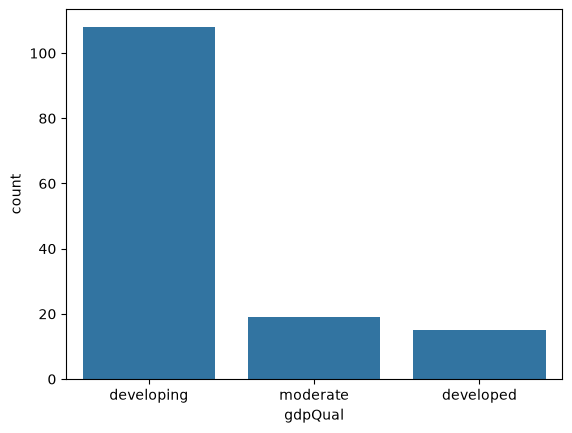

In [40]:
sns.countplot(
    data=data2002, # give data
    x='gdpQual', # choose column
    order=["developing", "moderate", "developed"]
)

---------

# 3. Time evolution

`Gapminder` captures global changes from $1952$ to $2007$. It is more insightful to examine how these variables evolve over time.

## 3.1. Evolution of quantitative columns

1. Create a line plot of `lifeExp` for the five continents from $1952$ to $2007$ using `sns.lineplot`. What observations can you make from the plot?

<Axes: xlabel='year', ylabel='lifeExp'>

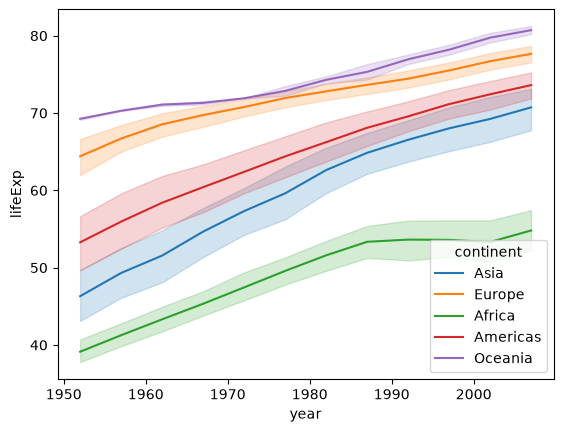

In [41]:
sns.lineplot(
    data=data, # give data
    x='year', # choose column for x-axis
    y='lifeExp', # choose column for y-axis
    hue='continent' # choose column for color
)

2. Repeat the same process with `pop`, and then with `gdpPercap`. Provide your comments for each case.

In [11]:
# To do

3. Plot the evolution of each of the three quantitative variables for **Cambodia** vs **Thailand**. Describe the graphs.

In [48]:
data_cam_thai = data.query("country in ['Cambodia', 'Thailand']")
data_cam_thai

,country,continent,year,lifeExp,pop,gdpPercap
216,Cambodia,Asia,1952,39.417,4693836,368.469286
217,Cambodia,Asia,1957,41.366,5322536,434.038336
218,Cambodia,Asia,1962,43.415,6083619,496.913648
219,Cambodia,Asia,1967,45.415,6960067,523.432314
220,Cambodia,Asia,1972,40.317,7450606,421.624026
221,Cambodia,Asia,1977,31.220,6978607,524.972183
222,Cambodia,Asia,1982,50.957,7272485,624.475478
223,Cambodia,Asia,1987,53.914,8371791,683.895573
224,Cambodia,Asia,1992,55.803,10150094,682.303175
225,Cambodia,Asia,1997,56.534,11782962,734.285170


<Axes: xlabel='year', ylabel='lifeExp'>

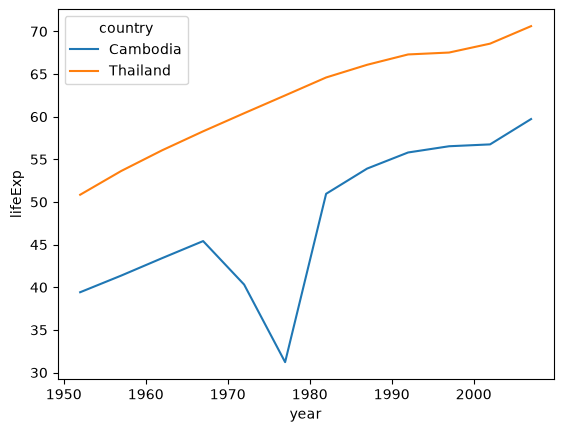

In [51]:
sns.lineplot(
    data=data_cam_thai,
    x='year',
    y='lifeExp',
    hue='country'
)

## 3.2. Evolution of qualitative columns

1. Visualize the evolution of `lifeExpQual` column in **Asia** from 1952 to 2007. What do you observe?

In [13]:
# To do

2. Do the same with `popQual` and `dgpQual` columns.

In [14]:
# To do

3. Visualize the evolution of the three qualitative columns above for African countries from 1952 to 2007.

# Further readings
- Gapminder documentation: [https://www.gapminder.org/data/documentation/](https://www.gapminder.org/data/documentation/)
- A short demonstration video is available here: [Hans Rosling's 200 Countries, 200 Years, 4 Minutes - The Joy of Stats - BBC Four](https://youtu.be/jbkSRLYSojo?si=qipg08VIi999hEgo).
- Graphical tools:
    - [`matplotlib`](https://matplotlib.org/stable/index.html)
    - [`seaborn`](https://seaborn.pydata.org/)
    - [`https://plotly.com/python/`](https://plotly.com/python/)